# Simulación de portafolios con Cholesky

**Simulación de Procesos Financieros**  
Ximena Muñoz  
11/11/2026

En esta actividad simulamos tres portafolios con AAPL, MSFT y NVDA. Primero usamos Cholesky para tomar en cuenta la relación entre las acciones y después comparamos las ganancias, las pérdidas, el VaR y el CVaR.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## 1. Precios y rendimientos

Descargamos los precios del último año de AAPL, MSFT y NVDA. Después calculamos sus rendimientos logarítmicos diarios.

In [2]:
tickers = ["AAPL", "MSFT", "NVDA"]

prices = yf.download(tickers=tickers, period="1y")["Close"]

prices = prices[tickers].dropna()

rets = np.log(prices / prices.shift(1)).dropna()

rets

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Date,,,
2025-11-13,-0.001903,-0.015477,-0.036467
2025-11-14,-0.001980,0.013597,0.017559
2025-11-17,-0.018338,-0.005287,-0.018951
2025-11-18,-0.000075,-0.027367,-0.028483
2025-11-19,0.004179,-0.013600,0.028055
...,...,...,...
2026-11-05,-0.015396,-0.036405,-0.097161
2026-11-06,-0.005244,-0.009976,0.027375
2026-11-09,0.024011,0.027089,-0.043641


### Correlación

Calculamos la correlación para ver qué tanto se relacionan los movimientos de las tres acciones.

In [3]:
rets.corr()

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.155491,0.059993
MSFT,0.155491,1.000000,0.233442
NVDA,0.059993,0.233442,1.000000


### Covarianza

Calculamos la matriz de covarianzas con los rendimientos diarios. Esta matriz también toma en cuenta qué tanto varían los rendimientos.

In [4]:
Sigma = rets.cov()*252
Sigma

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.062696,0.013119,0.005809
MSFT,0.013119,0.113541,0.030416
NVDA,0.005809,0.030416,0.149516


### Cholesky

Usamos la descomposición de Cholesky para generar movimientos que tomen en cuenta la relación entre las acciones.

In [5]:
L = np.linalg.cholesky(Sigma)
L

array([[0.25039215, 0.        , 0.        ],
       [0.0523941 , 0.33286043, 0.        ],
       [0.02319762, 0.08772575, 0.37587503]])

### Rendimiento promedio anual

Calculamos el promedio de los rendimientos logarítmicos y lo multiplicamos por 252 días para estimar el rendimiento anual.

In [6]:
mu = rets.mean().values * 252
mu

array([ 0.2675405 ,  0.02777033, -0.10778689])

### Rendimiento y volatilidad

Mostramos el rendimiento promedio anual, la volatilidad anual y las fechas de los datos que usamos.

In [7]:
print("Rendimientos promedio anuales (%):")
print((rets.mean() * 252 * 100).round(2))

print("\nVolatilidades anuales (%):")
print((rets.std() * np.sqrt(252) * 100).round(2))

print("\nPeriodo utilizado:")
print(f"Del {prices.index.min().date()} al {prices.index.max().date()}")

Rendimientos promedio anuales (%):
Ticker
AAPL    26.75
MSFT     2.78
NVDA   -10.78
dtype: float64

Volatilidades anuales (%):
Ticker
AAPL    25.04
MSFT    33.70
NVDA    38.67
dtype: float64

Periodo utilizado:
Del 2025-11-12 al 2026-11-11


## 2. Simulación de precios

Generamos 10,000 escenarios aleatorios con una semilla fija para obtener los mismos resultados cada vez que ejecutamos el código.

In [8]:
# Simulamos epsilon
M = 10000

np.random.seed(67)

epsilon = np.random.normal(0, 1, (3, M))

epsilon

array([[ 1.12852215,  0.14419228, -1.1152586 , ...,  0.75081834,
        -1.92303974, -0.66592187],
       [ 0.1190571 , -0.57445517,  0.93767601, ..., -0.20231816,
        -0.35610622,  1.07813835],
       [ 0.35372117,  1.0521816 ,  1.02902797, ...,  0.00457727,
         0.42838745,  2.03701049]])

### Movimientos correlacionados

Multiplicamos los números aleatorios por la matriz de Cholesky. Así los movimientos simulados consideran la covarianza entre las acciones.

In [9]:
Z = L @ epsilon
Z.T

array([[ 0.28257309,  0.09875731,  0.16957836],
       [ 0.03610462, -0.18365857,  0.3484392 ],
       [-0.279252  ,  0.25368226,  0.44317292],
       ...,
       [ 0.18799902, -0.02800526,  0.00138916],
       [-0.48151406, -0.21928961,  0.08517052],
       [-0.16674161,  0.32397922,  0.84479409]])

### Precios futuros

Con los movimientos obtenidos mediante Cholesky simulamos los precios de las tres acciones dentro de un año. Como utilizamos la matriz de covarianzas anualizada, ya estamos tomando en cuenta la volatilidad anual y no necesitamos multiplicarla otra vez.

In [10]:
# Tiempo de simulación: un año
T = 1
n_act = len(tickers)

ST = np.zeros((M, n_act))

cont = 0

for i in tickers:
    S0 = prices.iloc[-1][i]
    mu = rets[i].mean() * 252

    ST[:, cont] = S0 * np.exp(mu * T + np.sqrt(T) * Z[cont, :])

    cont += 1

ST

array([[616.46679674, 591.42044688, 184.80363182],
       [481.8033248 , 445.9073987 , 220.99822153],
       [351.48933711, 690.52497275, 242.95794766],
       ...,
       [560.8370469 , 521.00759491, 156.19490537],
       [287.12490185, 430.29897613, 169.84495239],
       [393.34605249, 740.81363601, 363.03873713]])

## 3. Portafolios

Comparamos tres formas de repartir un capital inicial de **100,000 USD**. Usamos dólares porque los precios de AAPL, MSFT y NVDA están en esa moneda.

- **Escenario 1:** 100% AAPL.
- **Escenario 2:** 33% AAPL, 33% MSFT y 34% NVDA.
- **Escenario 3:** 20% AAPL, 20% MSFT y 60% NVDA.

In [11]:
V0 = 100000

pesos = {
    "Escenario 1": np.array([1.00, 0.00, 0.00]),
    "Escenario 2": np.array([0.33, 0.33, 0.34]),
    "Escenario 3": np.array([0.20, 0.20, 0.60])
}

pd.DataFrame(pesos, index=tickers).T

,AAPL,MSFT,NVDA
Escenario 1,1.00,0.00,0.00
Escenario 2,0.33,0.33,0.34
Escenario 3,0.20,0.20,0.60


### Valor final de los portafolios

Calculamos cuántas acciones compraríamos con cada reparto y cuánto valdría cada portafolio al terminar el año.

In [12]:
# Precios iniciales
S0 = prices.iloc[-1].values

resultados = {}

for nombre, w in pesos.items():

    acciones = V0 * w / S0

    VT = ST @ acciones

    PnL = VT - V0

    resultados[nombre] = {
        "VT": VT,
        "PnL": PnL
    }

pd.DataFrame({
    nombre: datos["VT"]
    for nombre, datos in resultados.items()
}).head()

,Escenario 1,Escenario 2,Escenario 3
0,173344.990096,130822.090630,121191.044162
1,135478.817362,116195.293381,120533.579874
2,98835.680984,123890.854375,130177.007920
3,177852.592101,107239.030553,94661.262016
4,125710.983968,96193.975294,90118.029001


### Gráfica del valor futuro

La gráfica compara los posibles valores finales. La línea punteada marca los 100,000 USD que invertimos al principio.

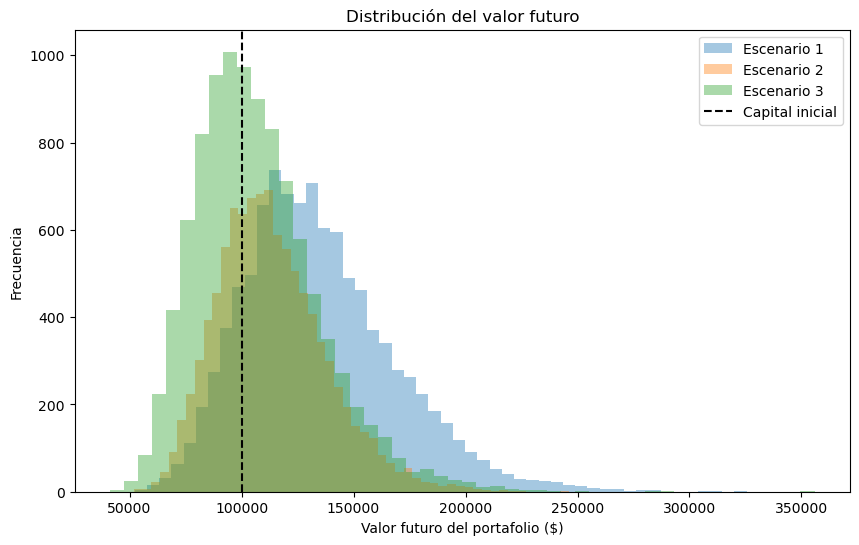

In [13]:
plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["VT"], bins=50, alpha=0.4, label=nombre)

plt.axvline(V0, color="black", linestyle="--", label="Capital inicial")
plt.title("Distribución del valor futuro")
plt.xlabel("Valor futuro del portafolio ($)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

## 4. Ganancias y pérdidas

Al valor final le restamos la inversión inicial:

$$P\&L = V_T - V_0$$

Si el resultado es negativo, perdimos dinero; si es positivo, ganamos.

In [14]:
pd.DataFrame({nombre: datos["PnL"] for nombre, datos in resultados.items()}).head()

,Escenario 1,Escenario 2,Escenario 3
0,73344.990096,30822.090630,21191.044162
1,35478.817362,16195.293381,20533.579874
2,-1164.319016,23890.854375,30177.007920
3,77852.592101,7239.030553,-5338.737984
4,25710.983968,-3806.024706,-9881.970999


### Gráfica de ganancias y pérdidas

Aquí comparamos las ganancias y pérdidas de los tres portafolios. La línea en cero indica que no ganamos ni perdimos.

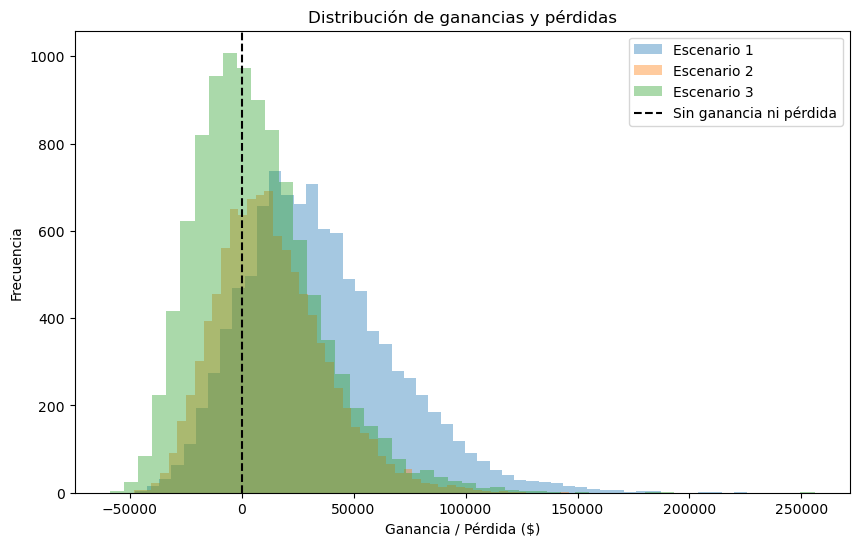

In [15]:
plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--", label="Sin ganancia ni pérdida")
plt.title("Distribución de ganancias y pérdidas")
plt.xlabel("Ganancia / Pérdida ($)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

### Promedios

Calculamos el valor final promedio y la ganancia promedio de cada escenario.

In [16]:
for nombre, datos in resultados.items():
    print(nombre)
    print(f"Valor final promedio: ${datos['VT'].mean():,.2f}")
    print(f"Ganancia promedio: ${datos['PnL'].mean():,.2f}")
    print()

Escenario 1
Valor final promedio: $134,772.61
Ganancia promedio: $34,772.61

Escenario 2
Valor final promedio: $113,330.72
Ganancia promedio: $13,330.72

Escenario 3
Valor final promedio: $106,962.13
Ganancia promedio: $6,962.13



### Comparación de escenarios

Comparamos la ganancia promedio, la volatilidad del rendimiento y la probabilidad de terminar con pérdidas.

In [17]:
resumen = []

for nombre, datos in resultados.items():
    pnl = datos["PnL"]
    resumen.append({
        "Escenario": nombre,
        "Valor futuro promedio ($)": datos["VT"].mean(),
        "Ganancia promedio ($)": pnl.mean(),
        "Volatilidad del rendimiento (%)": np.std(pnl / V0, ddof=1) * 100,
        "Probabilidad de pérdida (%)": np.mean(pnl < 0) * 100
    })

comparacion = pd.DataFrame(resumen).set_index("Escenario")
comparacion.round(2)

,Valor futuro promedio ($),Ganancia promedio ($),Volatilidad del rendimiento (%),Probabilidad de pérdida (%)
Escenario,,,,
Escenario 1,134772.61,34772.61,34.10,14.09
Escenario 2,113330.72,13330.72,24.28,31.40
Escenario 3,106962.13,6962.13,27.57,45.07


## 5. VaR y CVaR al 95%

Ahora revisamos el **5% de los peores resultados** de cada portafolio.

- **VaR:** nos indica el nivel de pérdida asociado a ese 5%.
- **CVaR:** es el promedio de los resultados dentro de ese 5% más desfavorable.

Los dos se calculan usando las ganancias y pérdidas simuladas.

In [18]:
# Nivel de confianza del 95%
alpha = 0.05

riesgos = []

for nombre, datos in resultados.items():

    pnl = datos["PnL"]

    # Percentil 5% de las ganancias y pérdidas
    q5 = np.percentile(pnl, 5)

    # VaR y CVaR
    VaR = -q5
    CVaR = -np.mean(pnl[pnl <= q5])

    riesgos.append({
        "Escenario": nombre,
        "VaR 95% ($)": VaR,
        "CVaR 95% ($)": CVaR
    })

tabla_riesgos = pd.DataFrame(riesgos).set_index("Escenario")

tabla_riesgos.round(2)

,VaR 95% ($),CVaR 95% ($)
Escenario,,
Escenario 1,13316.63,21542.47
Escenario 2,21766.30,27786.21
Escenario 3,30616.41,36593.35


### Gráficas del VaR

En cada gráfica, la línea roja marca el límite del 5% de los peores resultados. La línea negra marca cero ganancias o pérdidas.

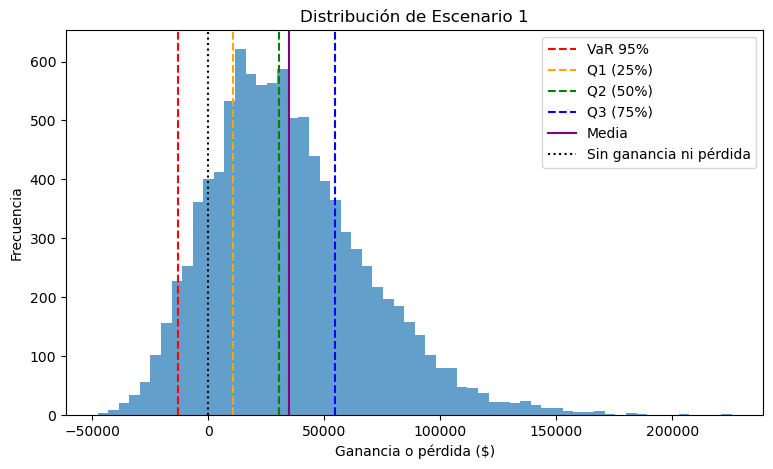

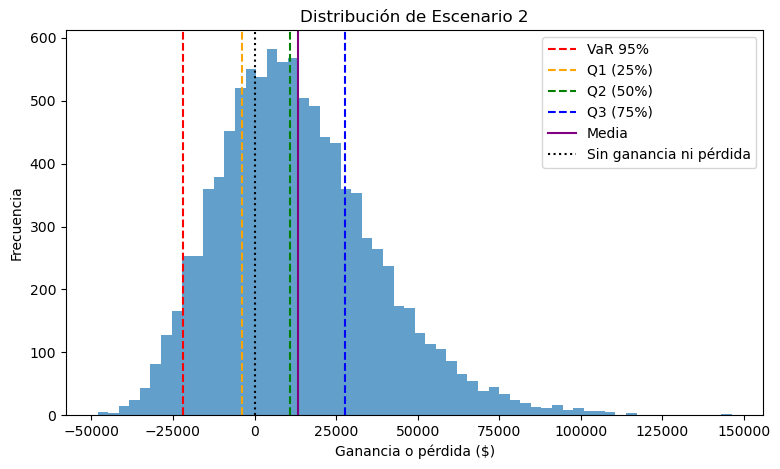

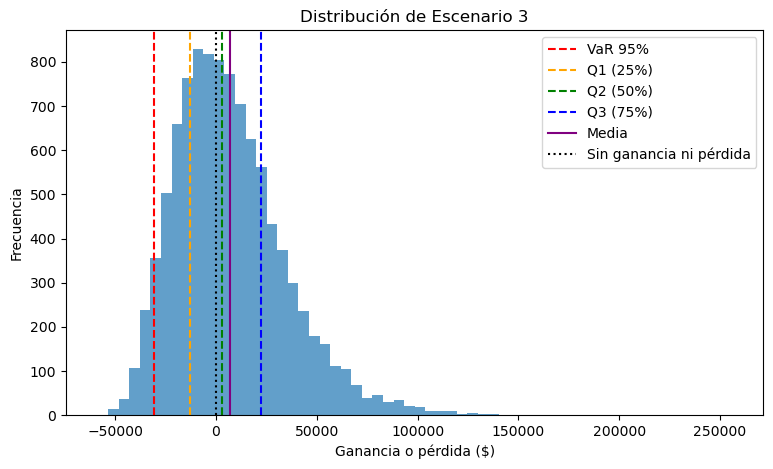

In [19]:

for nombre, datos in resultados.items():

    pnl = datos["PnL"]

    # Calculamos la media, el VaR y los cuartiles
    media = np.mean(pnl)
    q5 = np.percentile(pnl, 5)
    q1 = np.percentile(pnl, 25)
    q2 = np.percentile(pnl, 50)
    q3 = np.percentile(pnl, 75)

    plt.figure(figsize=(9, 5))

    plt.hist(pnl, bins=60, alpha=0.7)

    plt.axvline(q5, color="red", linestyle="--", label="VaR 95%")
    plt.axvline(q1, color="orange", linestyle="--", label="Q1 (25%)")
    plt.axvline(q2, color="green", linestyle="--", label="Q2 (50%)")
    plt.axvline(q3, color="blue", linestyle="--", label="Q3 (75%)")
    plt.axvline(media, color="purple", linestyle="-", label="Media")

    plt.axvline(0, color="black", linestyle=":", label="Sin ganancia ni pérdida")

    plt.title(f"Distribución de {nombre}")
    plt.xlabel("Ganancia o pérdida ($)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.show()



### Comparación de VaR, CVaR y Media

En esta gráfica comparamos el VaR, el CVaR y la media de los tres portafolios. El VaR y el CVaR nos ayudan a identificar las posibles pérdidas en los peores escenarios, mientras que la media representa la ganancia o pérdida promedio de las simulaciones.

Esto nos permite comparar tanto el riesgo como los resultados promedio de cada portafolio.

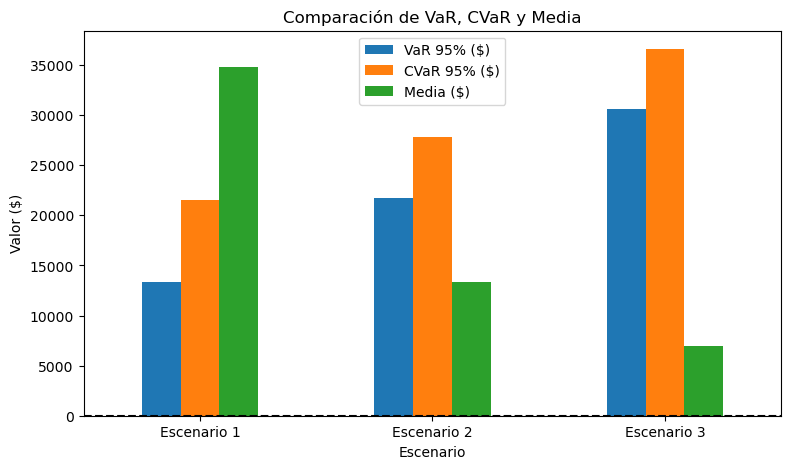

In [20]:
# Calculamos la media de cada portafolio
for nombre, datos in resultados.items():
    tabla_riesgos.loc[nombre, "Media ($)"] = np.mean(datos["PnL"])

# Gráfica de comparación
tabla_riesgos.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparación de VaR, CVaR y Media")
plt.ylabel("Valor ($)")
plt.xlabel("Escenario")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linestyle="--")
plt.legend()
plt.show()


## 6. Conclusión

En esta actividad usamos Cholesky para simular los precios de tres acciones tomando en cuenta cómo se relacionan. Después comparamos tres formas de invertir y calculamos sus posibles ganancias y pérdidas. Con el VaR y el CVaR también pudimos revisar qué pasa en los escenarios menos favorables. Aprendimos que cambiar los porcentajes de inversión puede cambiar el riesgo del portafolio.